In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import ExponentialLR

from tqdm.notebook import tqdm

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import clear_output

from datasets import load_dataset
from transformers import AutoTokenizer
from transformers import DataCollatorWithPadding
from transformers import AutoModel

import gc
from collections import defaultdict
import typing as tp
import numpy as np
import copy
import pickle


In [2]:
dataset = load_dataset("ag_news")

'[Errno 101] Network is unreachable' thrown while requesting HEAD https://huggingface.co/datasets/ag_news/resolve/eb185aade064a813bc0b7f42de02595523103ca4/ag_news.py
Retrying in 1s [Retry 1/5].
Using the latest cached version of the dataset since ag_news couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'default' at /home/administrator/.cache/huggingface/datasets/ag_news/default/0.0.0/eb185aade064a813bc0b7f42de02595523103ca4 (last modified on Sun Apr  5 18:10:41 2026).


In [6]:
class MiniBert(nn.Module):
    def __init__(self, bert_model, hidden_state, num_classes):
        super(MiniBert, self).__init__()
        self._bert_model = bert_model
        self.fc = nn.Linear(hidden_state, num_classes)

    def forward(self, input, attention_mask):
        bert_output = self._bert_model(input, attention_mask).pooler_output
        return self.fc(bert_output)


In [7]:
def plot_loss(values: defaultdict, suptitle: str, filename: str = '__file.pt'):
    clear_output()
    with sns.plotting_context("notebook"), sns.axes_style("darkgrid"):
        plt.figure(figsize=(28, 6), dpi=120)

        subplots_shape = (1, 3)

        plt.suptitle(suptitle)

        plt.subplot(*subplots_shape, 1)
        train_loss = values["train_loss"]
        plt.plot(range(1, len(train_loss) + 1), train_loss)
        plt.title('Train loss')
        plt.xlabel("Iterations")

        plt.subplot(*subplots_shape, 2)
        test_accuracy = values["test_accuracy"]
        plt.plot(range(1, len(test_accuracy) + 1), test_accuracy)
        plt.title('Test accuracy')
        plt.yticks(fontsize=10)
        plt.xlabel("Epochs")

        # plt.subplot(*subplots_shape, 3)
        # error = values["alpha_16/32"]
        # plt.plot(range(1, len(error) + 1), error)
        # plt.title(r'$\alpha$ - relative noise coefficient fp32 $\to$ fp16')
        # plt.xlabel("Iterations")
        
        plt.subplot(*subplots_shape, 3)
        error = values["alpha_16/64"]
        plt.plot(range(1, len(error) + 1), error)
        plt.title(r'$\alpha$ - relative noise coefficient fp64 $\to$ fp16')
        plt.xlabel("Iterations")

        # plt.subplot(*subplots_shape, 5)
        # error = values["alpha_32/64"]
        # plt.plot(range(1, len(error) + 1), error)
        # plt.title(r'$\alpha$ - relative noise coefficient fp64 $\to$ fp32')
        # plt.xlabel("Iterations")

        plt.savefig(f'./output/{filename}.pdf')

        plt.show()

In [8]:
def get_list_grad_params(net: nn.Module) -> tp.List[torch.Tensor]:
    return [param.grad.detach().cpu() for param in net.parameters() if param.grad is not None]

def calc_grad_info(net: nn.Module, info: tp.List[torch.Tensor]):
    new_grads = get_list_grad_params(net)
    if not info:
        return new_grads
    return [new_grad + cur_grad for new_grad, cur_grad in zip(new_grads, info)]

def get_dif(grad_info_1: tp.List[torch.Tensor], grad_info_2: tp.List[torch.Tensor]) -> tp.List[torch.Tensor]:
    return [grad_1 - grad_2 for grad_1, grad_2 in zip(grad_info_1, grad_info_2)]

def mult_grad(info: tp.List[torch.Tensor], mult: float):
    return [grad * mult for grad in info] 

def get_grad_norm(grads: tp.List[torch.Tensor]):
    return np.sqrt(sum(grad.norm().item() ** 2 for grad in grads))


In [9]:
def train_cycle(
    model,
    optim,
    scheduler,
    criterion,
    epochs,
    device,
    train_dataloader,
    test_dataloader,
    output_suptitle,
    output_filename,
    verbose=True,
):
    history = defaultdict(list)

    for _ in range(epochs):
        model.train()

        for x, attention_mask, y in tqdm(train_dataloader):
            full_grad_16 = []
            full_grad_64 = []

            attention_mask = attention_mask.to(device).type(torch.int)

            optim.zero_grad()
            model_cp = copy.deepcopy(model).half()
            model_cp.train()
            x = x.to(device)
            logits = model_cp(x, attention_mask)
            y_ = y.to(device)
            loss_batch = criterion(logits, y_)
            loss_batch.backward()
            full_grad_16 = calc_grad_info(model_cp, full_grad_16)

            optim.zero_grad()
            x = x.to(device)
            logits = model(x, attention_mask)
            y_ = y.to(device)
            loss_batch = criterion(logits, y_)
            loss_batch.backward()
            full_grad_64 = calc_grad_info(model, full_grad_64)

            history["alpha_16/64"].append(get_grad_norm(get_dif(full_grad_16, full_grad_64)) / get_grad_norm(full_grad_64))
            #history["alpha_16/32"].append(get_grad_norm(get_dif(full_grad_16, full_grad_32)) / get_grad_norm(full_grad_32))
            #history["alpha_32/64"].append(get_grad_norm(get_dif(full_grad_32, full_grad_64)) / get_grad_norm(full_grad_64))

            optim.step()
            loss_ = loss_batch.detach().item()
            history["train_loss"].append(loss_)
            del x
            del y
            del y_
            if 'cuda' in device:
                torch.cuda.synchronize()
                torch.cuda.empty_cache()
                gc.collect()

        scheduler.step()

        model.eval()
        with torch.no_grad():
            accuracy = 0
            total = 0
            for x, attention_mask, y in test_dataloader:
                data, attention_mask, target = x.to(device), attention_mask.to(device).type(torch.int), y
                output = model(data, attention_mask)
                pred = output.argmax(dim=1, keepdim=True).T[0].cpu()
                accuracy += pred.eq(target.view_as(pred)).sum().item()
                total += len(y)
            history["test_accuracy"].append(accuracy / total)

        if verbose:
            plot_loss(history, output_suptitle, output_filename)

    return model, history

In [10]:
BERT_CHECKPOINT = "prajjwal1/bert-mini"
TOKENIZER = AutoTokenizer.from_pretrained(BERT_CHECKPOINT, revision="refs/pr/6")
DATA_COLLATOR = DataCollatorWithPadding(tokenizer=TOKENIZER)

def collate_batch(batch):
    label_list, text_list = [], []
    for data in batch:
        x = data['text']
        y = data['label']
        label_list.append(y)
        processed_text = TOKENIZER(x)
        text_list.append(processed_text)
    label_list = torch.tensor(label_list, dtype=torch.int64)
    text_info = DATA_COLLATOR(text_list)
    return text_info['input_ids'], text_info['attention_mask'], label_list

In [26]:
device = "cuda:0" if torch.cuda.is_available() else "cpu"

batch_size: int = 512
num_class = 4
hidden_dim = 256

workers: int = 12
learning_rate = 2e-5

suptitle = 'MINI BERT AG-NEWS, floating point gradient quantization'
output_filename = 'mini_bert_fp'

dataloader_train = DataLoader(dataset['train'], batch_size=batch_size, shuffle=True, collate_fn=collate_batch, num_workers=workers)
dataloader_test = DataLoader(dataset['test'], batch_size=batch_size, shuffle=True, collate_fn=collate_batch, num_workers=workers)

bert_model = AutoModel.from_pretrained(BERT_CHECKPOINT, revision="refs/pr/6")


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

BertModel LOAD REPORT from: prajjwal1/bert-mini
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.embeddings.position_ids               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [27]:
for name, param in bert_model.named_parameters():
    param.requires_grad = False
    # print(name, param)

for p in list(bert_model.parameters())[-2:]:
    p.requires_grad = True

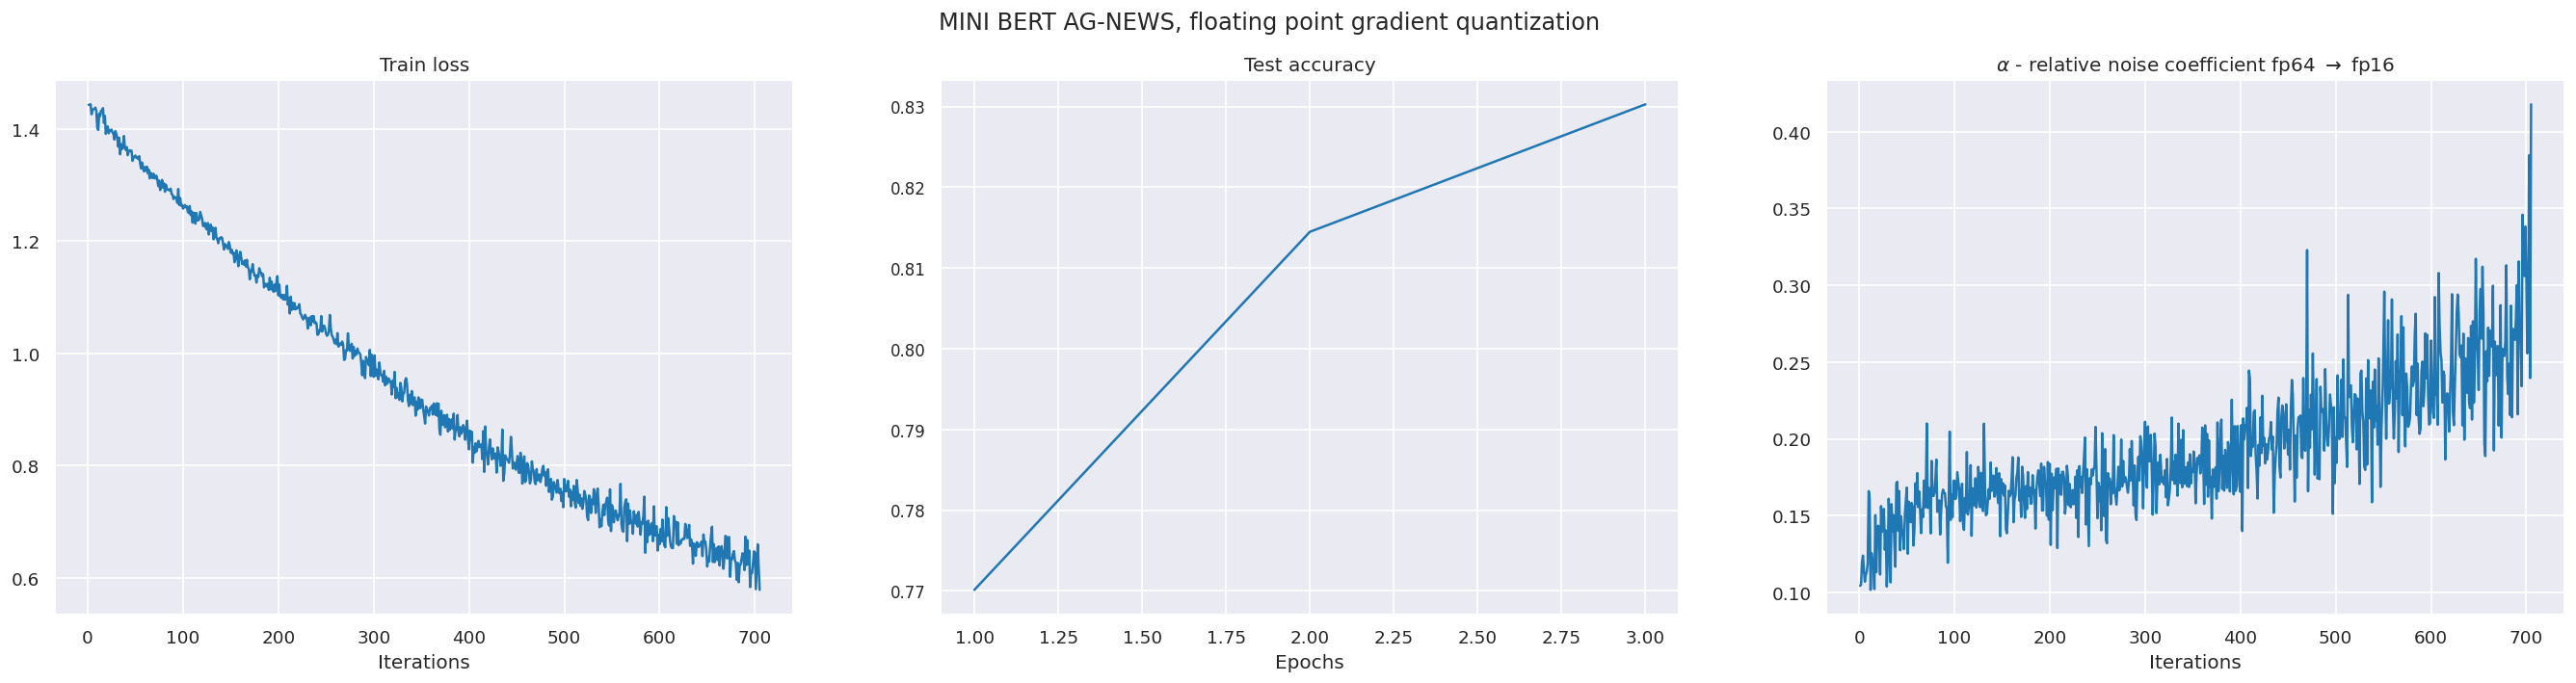

  0%|          | 0/235 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [28]:
model = MiniBert(bert_model, hidden_dim, num_class).to(device).double()

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scheduler = ExponentialLR(optimizer, gamma=0.98)
criterion = nn.CrossEntropyLoss()
verbose = True

epochs = 10

model, history = train_cycle(model,
                             optimizer,
                             scheduler,
                             criterion,
                             epochs,
                             device,
                             dataloader_train,
                             dataloader_test,
                             output_suptitle=suptitle,
                             output_filename=output_filename,
                             verbose=True)


In [25]:
with open('./dump_result/mini_bert_fp_1.pickle', 'wb') as f:
    pickle.dump(history, f)


In [13]:
torch.save(model.state_dict(), './models_coefs/mini_bert.pt')